# Assignment 3:
### DBSCAN
Date: September 30, 2026

Report produced by:  
COMP 3705 Group 3

## Load the data and inspect the header

In [60]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Load the dataset
df_patients = pd.read_csv("patient_priority.csv")
df_patients.head(10)
# df_patients[df_patients["Unnamed: 0"].duplicated() == True]

,Unnamed: 0,age,gender,chest pain type,blood pressure,cholesterol,max heart rate,exercise angina,plasma glucose,skin_thickness,insulin,bmi,diabetes_pedigree,hypertension,heart_disease,Residence_type,smoking_status,triage
0,0,40.0,1.0,2.0,140.0,294.0,172.0,0.0,108.0,43.0,92.0,19.0,0.467386,0.0,0.0,Urban,never smoked,yellow
1,1,49.0,0.0,3.0,160.0,180.0,156.0,0.0,75.0,47.0,90.0,18.0,0.467386,0.0,0.0,Urban,never smoked,orange
2,2,37.0,1.0,2.0,130.0,294.0,156.0,0.0,98.0,53.0,102.0,23.0,0.467386,0.0,0.0,Urban,never smoked,yellow
3,3,48.0,0.0,4.0,138.0,214.0,156.0,1.0,72.0,51.0,118.0,18.0,0.467386,0.0,0.0,Urban,never smoked,orange
4,4,54.0,1.0,3.0,150.0,195.0,156.0,0.0,108.0,90.0,83.0,21.0,0.467386,0.0,0.0,Urban,never smoked,yellow
5,5,39.0,1.0,3.0,120.0,294.0,170.0,0.0,86.0,49.0,106.0,21.0,0.467386,0.0,0.0,Urban,never smoked,orange
6,6,45.0,0.0,2.0,130.0,237.0,170.0,0.0,116.0,39.0,97.0,23.0,0.467386,0.0,0.0,Urban,never smoked,yellow
7,7,54.0,1.0,2.0,110.0,208.0,142.0,0.0,124.0,82.0,103.0,19.0,0.467386,0.0,0.0,Urban,never smoked,yellow
8,8,37.0,1.0,4.0,140.0,207.0,142.0,1.0,84.0,67.0,120.0,22.0,0.467386,0.0,0.0,Urban,never smoked,orange
9,9,48.0,0.0,2.0,120.0,294.0,142.0,0.0,77.0,37.0,90.0,18.0,0.467386,0.0,0.0,Urban,never smoked,yellow


In [61]:
data_shape = df_patients.shape
columns = list(df_patients.columns)
print("Shape: ", data_shape,'\n',columns)
df_patients.describe()
# df_patients = df_patients.drop(columns="triage")
df_patients.head(10)

Shape:  (6962, 18) 
 ['Unnamed: 0', 'age', 'gender', 'chest pain type', 'blood pressure', 'cholesterol', 'max heart rate', 'exercise angina', 'plasma glucose', 'skin_thickness', 'insulin', 'bmi', 'diabetes_pedigree', 'hypertension', 'heart_disease', 'Residence_type', 'smoking_status', 'triage']


,Unnamed: 0,age,gender,chest pain type,blood pressure,cholesterol,max heart rate,exercise angina,plasma glucose,skin_thickness,insulin,bmi,diabetes_pedigree,hypertension,heart_disease,Residence_type,smoking_status,triage
0,0,40.0,1.0,2.0,140.0,294.0,172.0,0.0,108.0,43.0,92.0,19.0,0.467386,0.0,0.0,Urban,never smoked,yellow
1,1,49.0,0.0,3.0,160.0,180.0,156.0,0.0,75.0,47.0,90.0,18.0,0.467386,0.0,0.0,Urban,never smoked,orange
2,2,37.0,1.0,2.0,130.0,294.0,156.0,0.0,98.0,53.0,102.0,23.0,0.467386,0.0,0.0,Urban,never smoked,yellow
3,3,48.0,0.0,4.0,138.0,214.0,156.0,1.0,72.0,51.0,118.0,18.0,0.467386,0.0,0.0,Urban,never smoked,orange
4,4,54.0,1.0,3.0,150.0,195.0,156.0,0.0,108.0,90.0,83.0,21.0,0.467386,0.0,0.0,Urban,never smoked,yellow
5,5,39.0,1.0,3.0,120.0,294.0,170.0,0.0,86.0,49.0,106.0,21.0,0.467386,0.0,0.0,Urban,never smoked,orange
6,6,45.0,0.0,2.0,130.0,237.0,170.0,0.0,116.0,39.0,97.0,23.0,0.467386,0.0,0.0,Urban,never smoked,yellow
7,7,54.0,1.0,2.0,110.0,208.0,142.0,0.0,124.0,82.0,103.0,19.0,0.467386,0.0,0.0,Urban,never smoked,yellow
8,8,37.0,1.0,4.0,140.0,207.0,142.0,1.0,84.0,67.0,120.0,22.0,0.467386,0.0,0.0,Urban,never smoked,orange
9,9,48.0,0.0,2.0,120.0,294.0,142.0,0.0,77.0,37.0,90.0,18.0,0.467386,0.0,0.0,Urban,never smoked,yellow


In [62]:
print(df_patients.shape)
df_patients.describe()

(6962, 18)


,Unnamed: 0,age,gender,chest pain type,blood pressure,cholesterol,max heart rate,exercise angina,plasma glucose,skin_thickness,insulin,bmi,diabetes_pedigree,hypertension,heart_disease
count,6962.000000,6962.000000,6961.000000,6962.000000,6962.000000,6962.000000,6962.000000,6962.000000,6962.000000,6962.000000,6962.000000,6962.000000,6962.000000,6962.000000,6962.000000
mean,2011.954180,57.450014,0.531964,0.529015,109.629991,184.711290,163.502442,0.061764,98.394283,56.813416,111.091640,27.190908,0.467386,0.071531,0.039500
std,1560.966466,11.904948,0.499013,1.253791,21.534852,32.010359,15.458693,0.240743,28.598084,22.889316,17.470033,7.362886,0.102663,0.257729,0.194796
min,0.000000,28.000000,0.000000,0.000000,60.000000,150.000000,138.000000,0.000000,55.120000,21.000000,81.000000,10.300000,0.078000,0.000000,0.000000
25%,604.000000,48.000000,0.000000,0.000000,92.000000,164.000000,150.000000,0.000000,78.707500,36.000000,97.000000,21.800000,0.467386,0.000000,0.000000
50%,1628.500000,56.000000,1.000000,0.000000,111.000000,179.000000,163.000000,0.000000,93.000000,55.000000,111.000000,26.200000,0.467386,0.000000,0.000000
75%,3368.750000,66.000000,1.000000,0.000000,127.000000,192.000000,177.000000,0.000000,111.632500,77.000000,125.000000,31.000000,0.467386,0.000000,0.000000
max,5109.000000,82.000000,1.000000,4.000000,165.000000,294.000000,202.000000,1.000000,199.000000,99.000000,171.000000,66.800000,2.420000,1.000000,1.000000


## Observations 
## Meaning of the Columns

- **Unnamed: 0**: serves as a primary key for the records.
- **age**: this is the Patient age.
- **gender**: it represented as 1/0 indicating there are only 2 genders represented .
- **chest pain type**: its shows type of chest pain experienced in 4 categories .
- **blood pressure**: Patients Blood pressure record.
- **cholesterol**: Patients cholesterol Record.
- **max heart rate**: Patients Maximum heart rate recorded.
- **exercise angina**: Records whether or not the patients experiences exercise angina.
- **plasma glucose**: Patients Plasma glucose recorded.
- **skin_thickness**: Patients skin-thickness recorded.
- **insulin**: Patients insulin recorded.
- **bmi**: Body mass index of the patient.
- **diabetes_pedigree**: Chances of patient getting Diabetes based on genetics.
- **hypertension**: Indicates whether or not the patient has hypertension.
- **heart_disease**: Indicates whether or not patient has heart disease.
- **Residence_type**: Patient residence category, such as Urban or Rural.
- **smoking_status**: Indicates the patients smoking Status.
- **triage** - ranks patient priority based on illness/injury, symptoms, severity, prognosis, and resource availability.  
                        Used to identify patients needing immediate care. From most urgent to least, Red, Yellow, Green, White. Black represents deceased or mortally wounded.

### Observations from the summary statistics

The dataset contains **6,962 patient records**. Age ranges from **28 to 82***. Blood pressure has a median of **111**, cholesterol has a median of **179**, and maximum heart rate has a median of **163**.

Several columns are binary variables, like gender, exercise angina, hypertension, and heart disease. The categorical columns are `Residence_type` and `smoking_status` .

The summary statistics are useful for understanding the spread of the numerical variablesin the dataset and will be good for identifying possible unusual occurences  where the values donmake sense. They also show that the dataset contains a mixture of continuous measurements, binary indicators, and categorical variables, so preprocessing is required before clustering.

## Check Datatypes Missing Values, & Duplicate Rows

In [63]:
df_patients.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6962 entries, 0 to 6961
Data columns (total 18 columns):
Unnamed: 0           6962 non-null int64
age                  6962 non-null float64
gender               6961 non-null float64
chest pain type      6962 non-null float64
blood pressure       6962 non-null float64
cholesterol          6962 non-null float64
max heart rate       6962 non-null float64
exercise angina      6962 non-null float64
plasma glucose       6962 non-null float64
skin_thickness       6962 non-null float64
insulin              6962 non-null float64
bmi                  6962 non-null float64
diabetes_pedigree    6962 non-null float64
hypertension         6962 non-null float64
heart_disease        6962 non-null float64
Residence_type       6962 non-null object
smoking_status       6962 non-null object
triage               6552 non-null object
dtypes: float64(14), int64(1), object(3)
memory usage: 979.1+ KB


In [64]:
print(df_patients["Residence_type"].value_counts())
print(df_patients["smoking_status"].value_counts())
print(df_patients["triage"].value_counts())

Urban    4449
Rural    2513
Name: Residence_type, dtype: int64
never smoked       3745
Unknown            1544
formerly smoked     884
smokes              789
Name: smoking_status, dtype: int64
yellow    5637
green      440
orange     346
red        129
Name: triage, dtype: int64


In [65]:
df_patients.isna().sum()

Unnamed: 0             0
age                    0
gender                 1
chest pain type        0
blood pressure         0
cholesterol            0
max heart rate         0
exercise angina        0
plasma glucose         0
skin_thickness         0
insulin                0
bmi                    0
diabetes_pedigree      0
hypertension           0
heart_disease          0
Residence_type         0
smoking_status         0
triage               410
dtype: int64

In [66]:
df_patients["Residence_type"] = df_patients["Residence_type"].map({"Urban": int(1),
                                                                   "Rural": int(0)})
# df_patients["triage"] = df_patients["triage"].map({"Red": int(5),
#                                                    "Orange": int(4),
#                                                    "Yellow": int(3),
#                                                    "Green": int(2),
#                                                    "White": int(1),
#                                                    "Black": int(0)
#                                                    })

In [67]:
"""
Since only one value out of 6962 entries has a missing gender and the value normals between male and female can vary drastically in medicine due to hormonal differences, we will drop this entry so as not to add inconsitencies. 
"""

df_patients[df_patients["gender"].isna() == True]
if df_patients["gender"].isna().sum() > 0:
    df_patients = df_patients.drop(index=4968)
df_patients.isna().sum()
# df_patients.duplicated().sum()

Unnamed: 0             0
age                    0
gender                 0
chest pain type        0
blood pressure         0
cholesterol            0
max heart rate         0
exercise angina        0
plasma glucose         0
skin_thickness         0
insulin                0
bmi                    0
diabetes_pedigree      0
hypertension           0
heart_disease          0
Residence_type         0
smoking_status         0
triage               410
dtype: int64

In [68]:
df_patients_cleaned = df_patients.copy()
# Remove the index/identifier column because it is not a patient feature
df_patients_cleaned = df_patients_cleaned.drop(columns="Unnamed: 0")
# Convert binary categorical variables from float  to integers
integer_columns = [
    "gender",
    "chest pain type",
    "exercise angina",
    "hypertension",
    "heart_disease"
] 
for column in integer_columns:
    df_patients_cleaned[column] = df_patients_cleaned[column].astype(int)

In [69]:
df_patients_cleaned.isna().sum()

age                    0
gender                 0
chest pain type        0
blood pressure         0
cholesterol            0
max heart rate         0
exercise angina        0
plasma glucose         0
skin_thickness         0
insulin                0
bmi                    0
diabetes_pedigree      0
hypertension           0
heart_disease          0
Residence_type         0
smoking_status         0
triage               410
dtype: int64

In [70]:
df_patients_cleaned.dtypes

age                  float64
gender                 int32
chest pain type        int32
blood pressure       float64
cholesterol          float64
max heart rate       float64
exercise angina        int32
plasma glucose       float64
skin_thickness       float64
insulin              float64
bmi                  float64
diabetes_pedigree    float64
hypertension           int32
heart_disease          int32
Residence_type         int64
smoking_status        object
triage                object
dtype: object

In [71]:
# df_features = 
# df_labels = 

### Findings and Cleaning
For the cleaning process the following was done:
- The only missing value in `gender` was replaced with the mode in the  `gender` column.
- The `triage` column was removed at the beginning asper the instructions.
- The `Unnamed: 0` was removed because it seved as an index column and the dataset was already doing that so it was repetitive.
- the Binary categorical numerical variables were converted to integer type as they did not need to be in float.
- Duplicate values were not present when cheked with `drop_duplicates()`.

## One-hot encoding categorical columns

In [72]:
categorical_string_columns = df_patients_cleaned.select_dtypes(include="object").columns
categorical_string_columns.tolist()
df_encoded = pd.get_dummies(df_patients_cleaned,columns=categorical_string_columns,dtype=int)
df_encoded.head()

,age,gender,chest pain type,blood pressure,cholesterol,max heart rate,exercise angina,plasma glucose,skin_thickness,insulin,...,heart_disease,Residence_type,smoking_status_Unknown,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes,triage_green,triage_orange,triage_red,triage_yellow
0,40.0,1,2,140.0,294.0,172.0,0,108.0,43.0,92.0,...,0,1,0,0,1,0,0,0,0,1
1,49.0,0,3,160.0,180.0,156.0,0,75.0,47.0,90.0,...,0,1,0,0,1,0,0,1,0,0
2,37.0,1,2,130.0,294.0,156.0,0,98.0,53.0,102.0,...,0,1,0,0,1,0,0,0,0,1
3,48.0,0,4,138.0,214.0,156.0,1,72.0,51.0,118.0,...,0,1,0,0,1,0,0,1,0,0
4,54.0,1,3,150.0,195.0,156.0,0,108.0,90.0,83.0,...,0,1,0,0,1,0,0,0,0,1


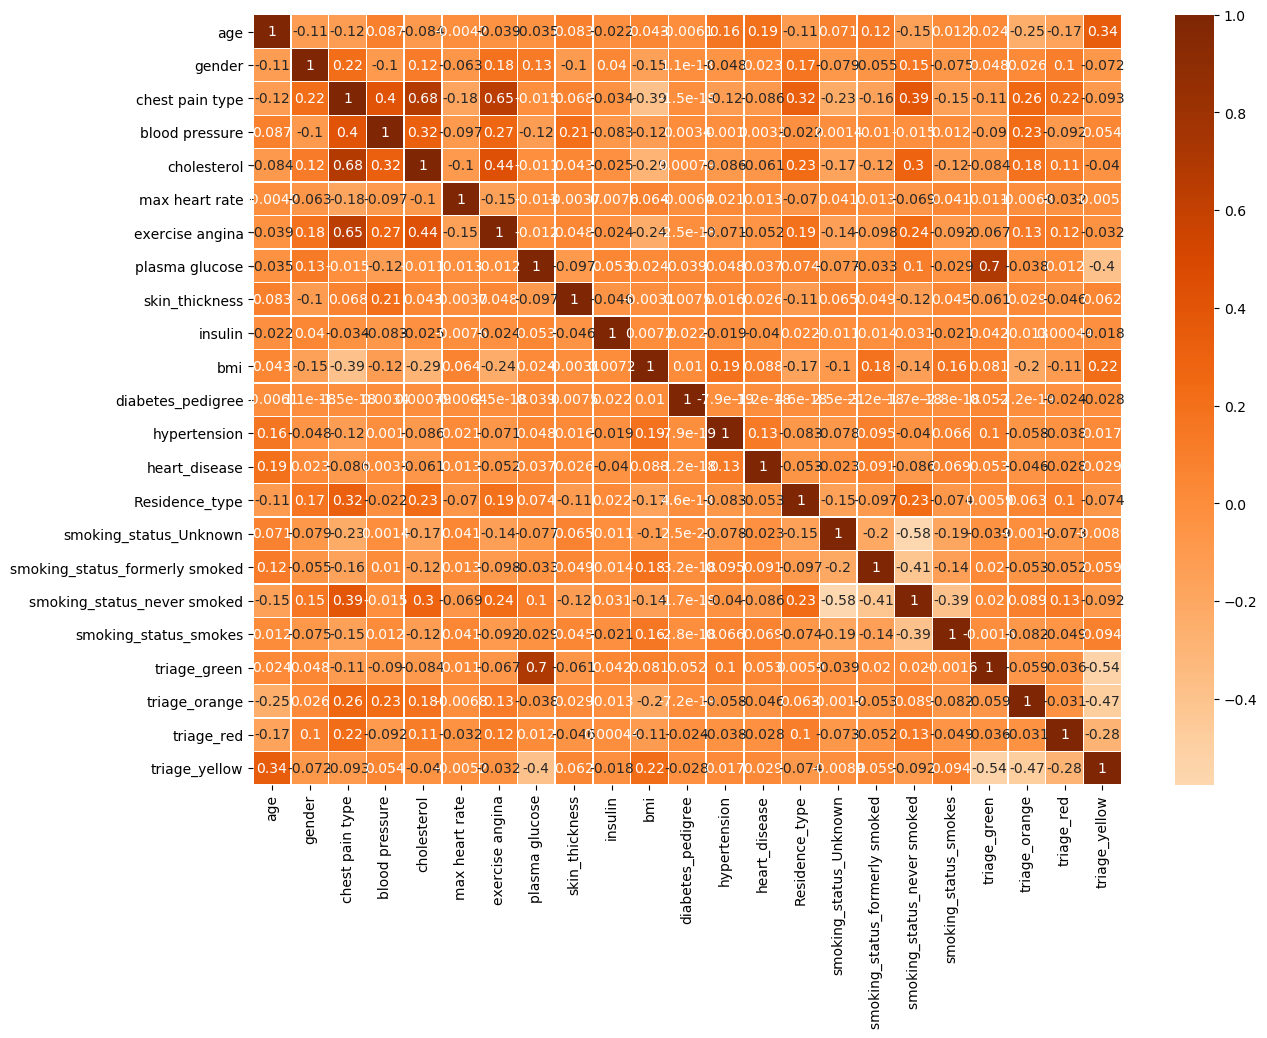

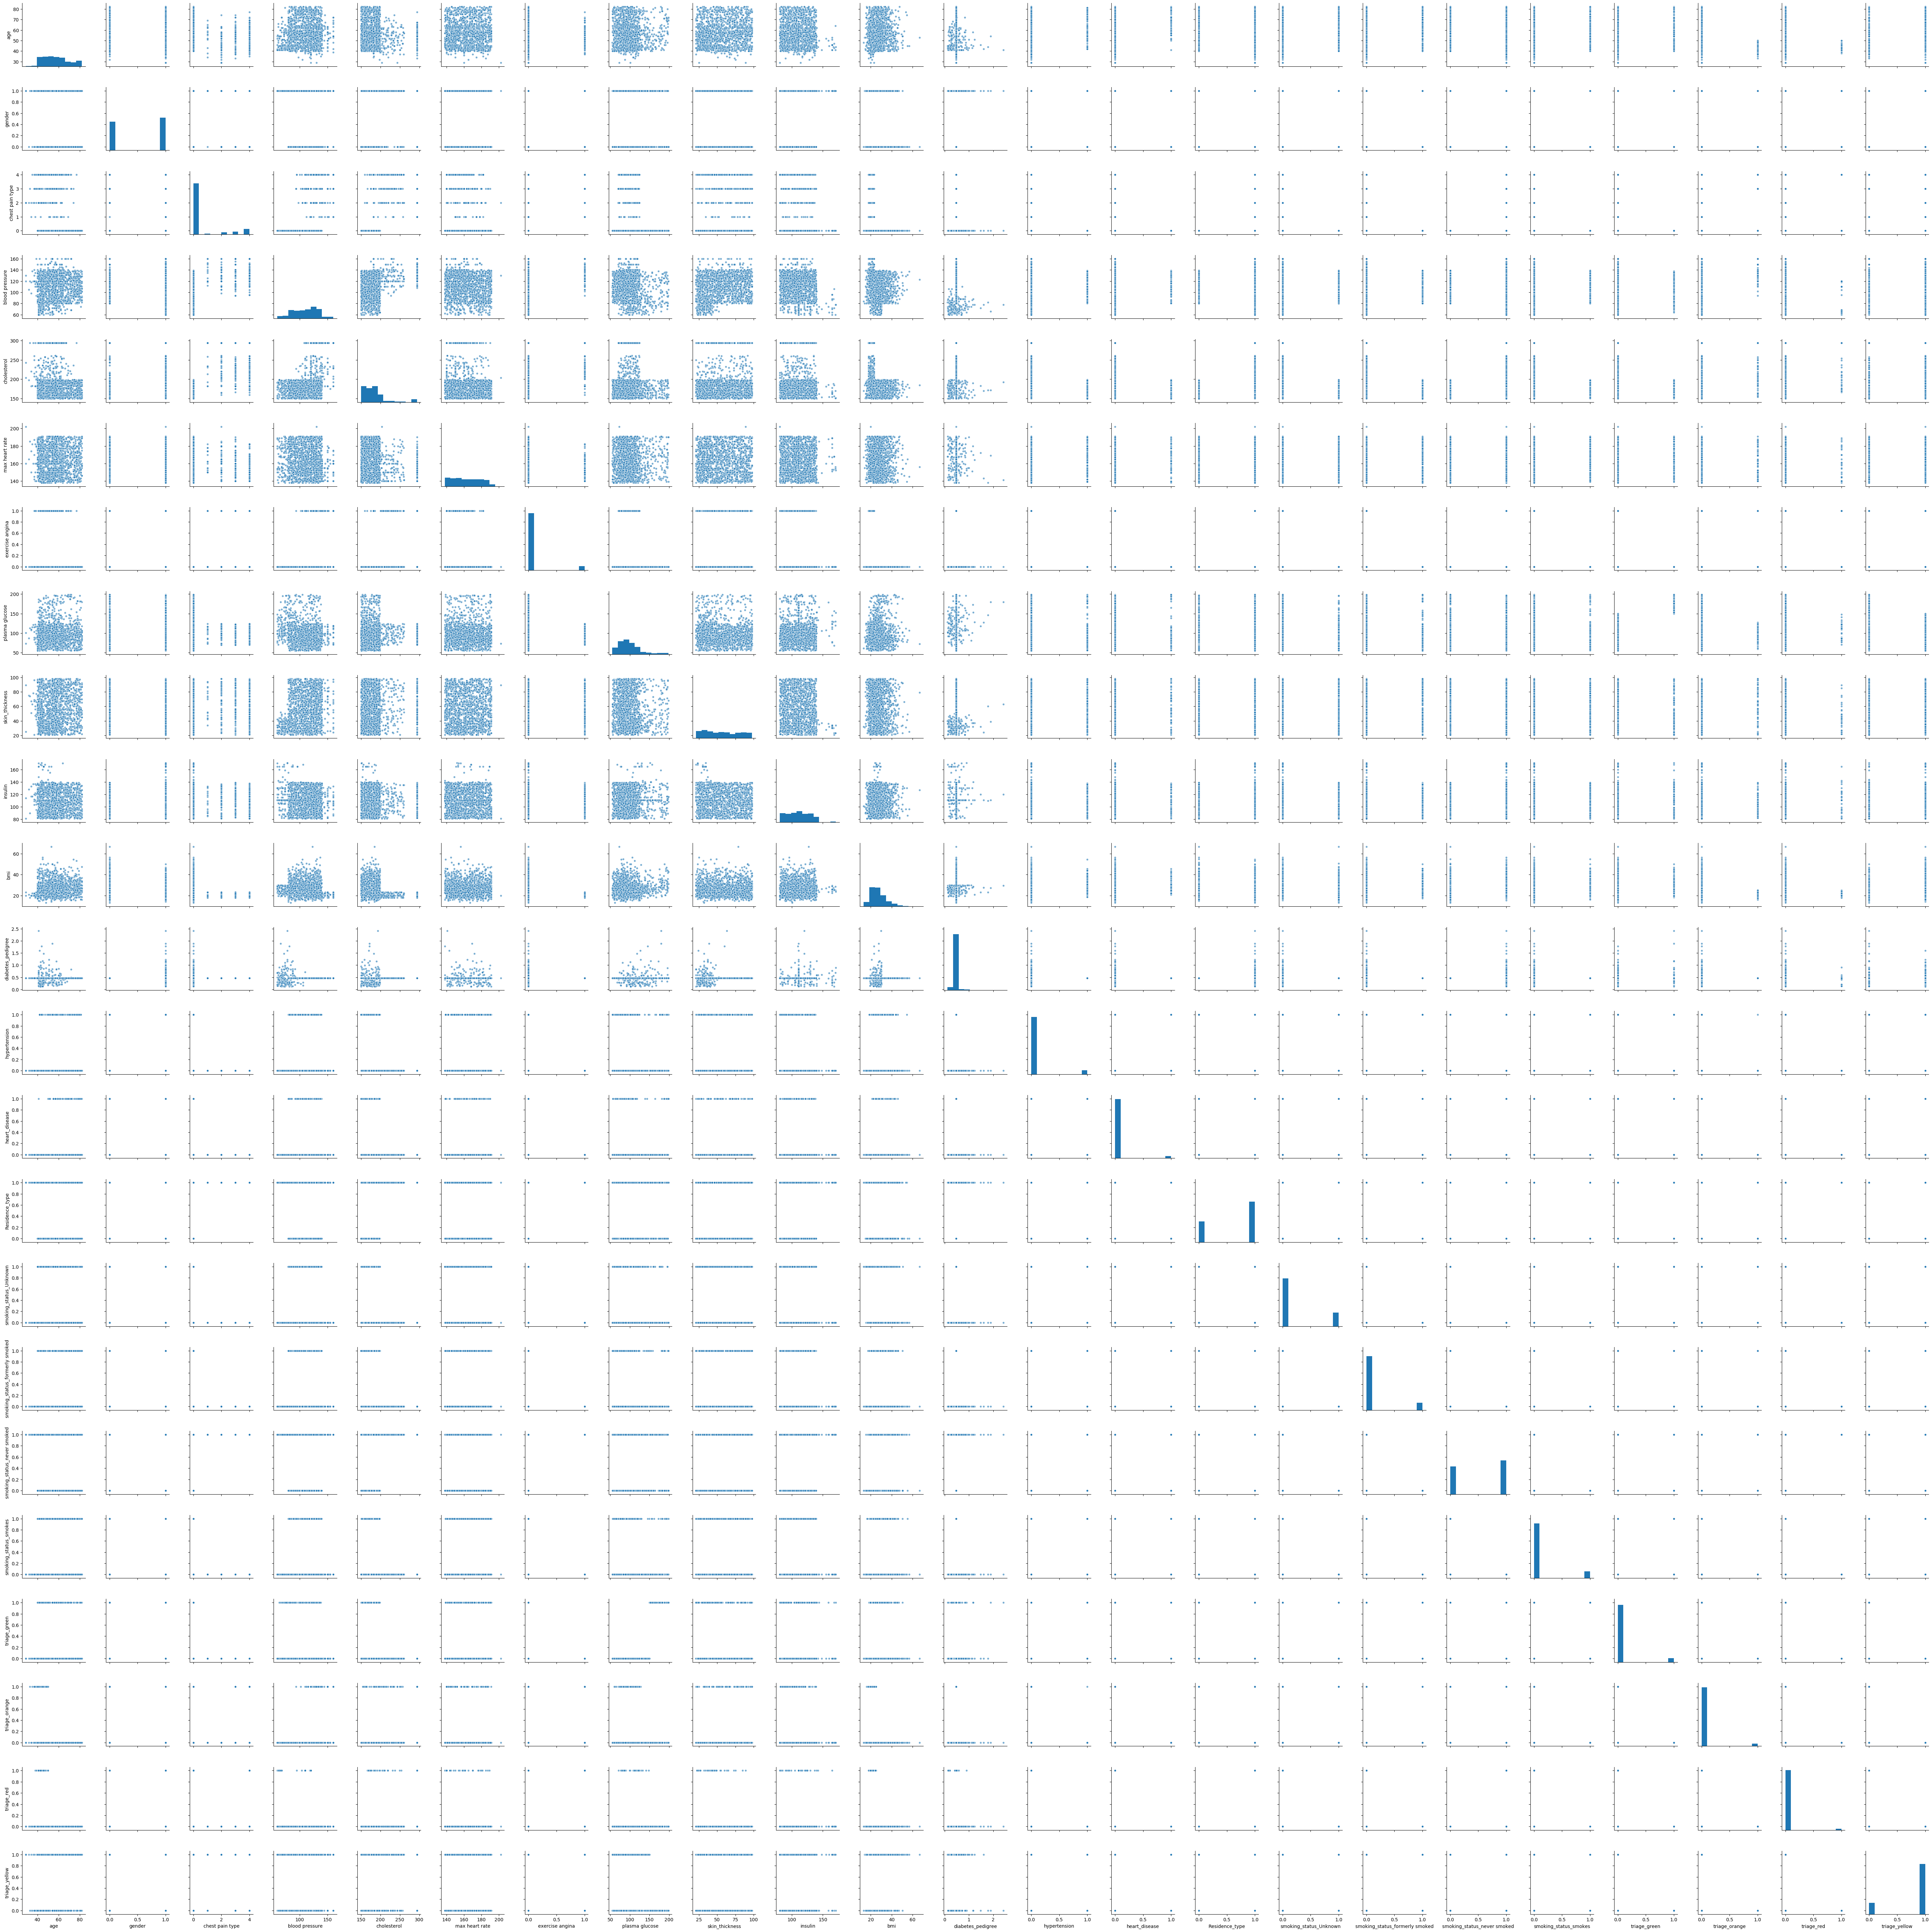

In [73]:
plt.figure(figsize=(14, 10))

# Plot a heatmap of the features correlation
sns.heatmap(df_encoded.corr(), annot=True, cmap="Oranges", center=0, linewidths=0.3)
plt.title("")
plt.show()

# Create a pairplot using a random sample of points (1500)
df_sample = df_encoded.sample(n=1500, random_state=42)
sns.pairplot(df_sample,diag_kind="hist",plot_kws={"alpha": 0.6, "s": 20})
plt.suptitle("", y=1.01)
plt.show()

## Correlation Matrix & Pairplot Observations

**Strong positive correlations:**  

**Negative correlations:**  

**Weak relationships:**  


### Pairplot (`seaborn.pairplot`) – Observations

**Histograms:**  

**Scatter plots:**  


## Model Selection


In [74]:
from sklearn.preprocessing import MinMaxScaler as scaler
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score as s_score, silhouette_samples as s_samples

def scale_df(df):
    return scaler().fit_transform(df)

def get_dbscan(x_val, eps_val, min_n, distance_metric, p_val):
    i = 0
    metrics = {}
    for dist in distance_metric:
        for n in min_n:
            for eps in eps_val:
                for p in p_val:
                    model_n = DBSCAN(eps, min_samples=n,metric=dist, p=p).fit(x_val)
                    model_metrics = {
                        "Iteration": i,
                        "Parameters": [eps, n, dist, p],
                        "Silhouette Score": s_score(x_val,labels,metric=dist),
                        "Silhouette Coefficients": s_samples(x_val,labels,metric=dist),
                        "Labels": model_n.labels_,
                        "Clusters Found": max(model_n.labels_),
                    }
                    i += 1
                    metrics[f"Iteration {i}"] = model_metrics
    return metrics

def plot_silhouette(metrics):
    # Plot Silhouette vs Cluster
    model_num = metrics["Iteration"]
    k = int(metrics["Clusters Found"])
    labels = metrics["Labels"]
    silhouette_avg = metrics["Silhouette Score"]
    silhouette_values = metrics["Silhouette Coefficients"]
    param = metrics["Parameters"]

    prev_cluster_size = 0
    silhouette_plot, axis = plt.subplots(figsize=(8,6))
    for i in range(0,k):
        tick_loc = []
        for n in range(k):
            nth_cluster_values = silhouette_values[labels==n]
            nth_cluster_values.sort()
            nth_cluster_size = len(nth_cluster_values)
            tick_loc.append(nth_cluster_size/2+prev_cluster_size)
            y_upper_bounds = prev_cluster_size + nth_cluster_size
            axis.fill_betweenx(np.arange(prev_cluster_size,y_upper_bounds),0,nth_cluster_values)
            prev_cluster_size += nth_cluster_size
        axis.set_yticks(tick_loc)
        axis.set_yticklabels(np.arange(1,n+2), fontsize=8)
        axis.axvline(silhouette_avg,c=(36/255.0, 9/255.0, 82/255.0),linestyle="--")
        axis .set_title(f"Silhouette Scores for Iteration {model_num}")
        axis.set_ylabel("Cluster")
        axis.set_xlabel("Silhouette Coefficient")
        plt.show()

In [75]:
df_scaled = scale_df(df_patients_cleaned)
db_metrics = get_dbscan(df_scaled,[],[0,10,15],["euclidean", "manhattan", "cosine"],[])

ValueError: could not convert string to float: 'never smoked'

## Conclusion

In [ ]:
chosen_model = 

labels = chosen_model["Labels"]
# Add cluster labels to the features DataFrame
df_clustered = df_features.copy()
df_clustered["Cluster"] = labels

# Plot Scatterplot of chosen features coloured by cluster
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_clustered,x="PURCHASES_FREQUENCY",y="CREDIT_LIMIT",hue=df_clustered["Cluster"],alpha=0.6,s=30)
plt.title(f"Customer Clusters: Purchase Frequency vs Credit Limit (Iteration 10)")
plt.xlabel("Purchase Frequency")
plt.ylabel("Credit Limit")
plt.legend(title="Cluster")
plt.show()

# Plot Histogram of chosen model cluster breakdown
plt.figure(figsize=(7, 5))
sns.countplot(data=df_clustered, x="Cluster", palette="tab10")
plt.title(f"Iteration 10: Cluster Distribution")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
for i, count in df_clustered["Cluster"].value_counts().sort_index().items():
    plt.text(i, count + 1, str(count), ha="center")
plt.show()

## Cluster Breakdowns

## Final Propositions


## Acknowledgment of Contributions
### Group 3 Members:  
Sebastian Levy  
Idongesit Orok  
Miracle Okojie  

### Task Distribution:  


We, Group 3, acknowledge that we understand all parts of this assignment, including those which we did not personally carry out.